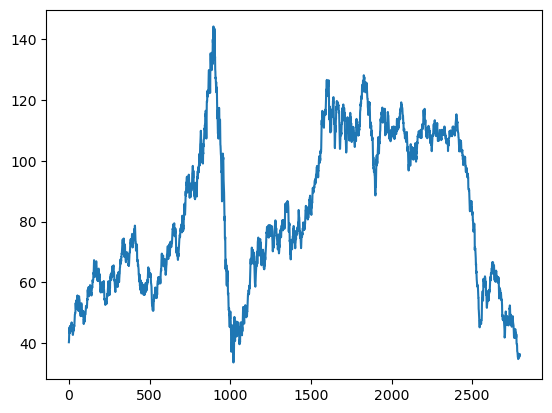

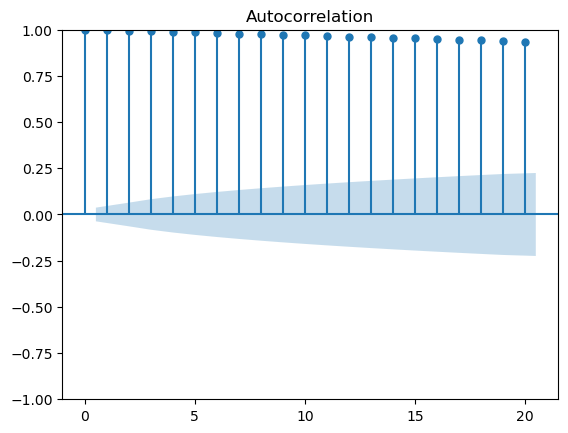

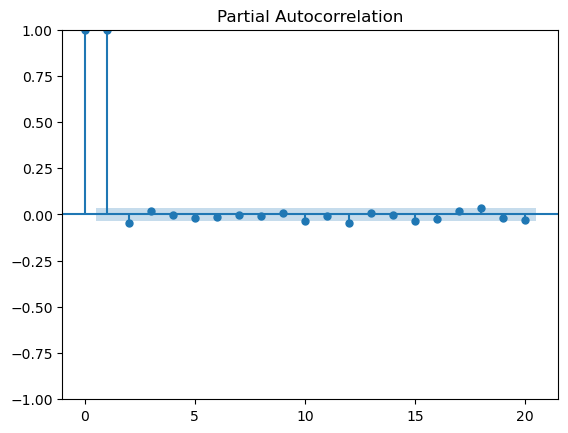

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

data = pd.read_csv('../data/Homework_1_DATA.csv', sep = ";", decimal = ",")
series7 = data.iloc[:200000,0]

y = series7 # CHANGE THE SERIES HERE

num_lags=20 # to discuss

plt.plot(y)
plt.show()
plot_acf(y,lags=num_lags)
plt.show()
plot_pacf(y,lags=num_lags,method="ols")
plt.show()


In [ ]:
from scipy.stats import kurtosis, skew

# Basic statistics
mean = np.mean(y)
std = np.std(y)
kurtosis = kurtosis(y)
skewness = skew(y)

print("Mean",mean,"Standard deviation",std,"Skewness", skewness, "Kurtosis",kurtosis)

# t-test for the mean with Ho equal to zero

t_statistic, p_value = stats.ttest_1samp(y, 0)

print(f"T-statistic: {t_statistic}")
print(f"P-value: {p_value}")


Mean 82.9486373390558 Standard deviation 25.29137540594164 Skewness 0.07675340964475884 Kurtosis -1.273679962331883
T-statistic: 173.39146422773402
P-value: 0.0


In [ ]:
#from pmdarima.arima.utils import ndiffs, nsdiffs
import statsmodels as sm

# Ho: the process is not stationary. We need, at least, a unit root
# H1: the process is stationary. We have to check different models (lags)


adf_test = sm.tsa.stattools.adfuller(y,maxlag=10)
# print("adf_test", adf_test) # first output "The test statistic", second output "p-value"
print("ADF test for the original series")
print("Statistic Value:" , adf_test[0])
print("p-value:" , adf_test[1])
# print(sm.__version__)

ADF test for the original series
Statistic Value: -1.578690150725415
p-value: 0.4942886750236335


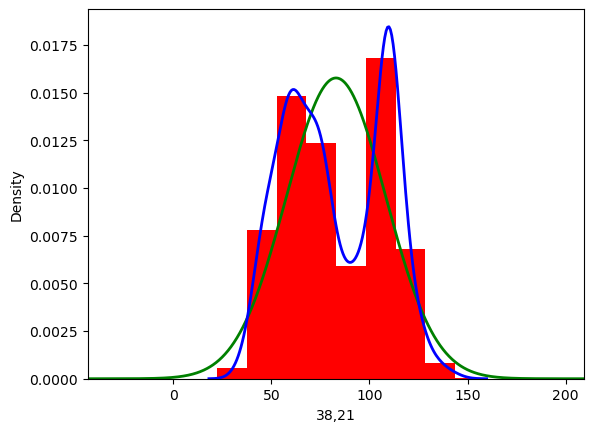

In [ ]:
import seaborn as sns
import scipy.stats as st

mu = np.mean(y)
sigma = np.std(y)
x = np.linspace(mu -5*sigma, mu +5*sigma, 1000)
pdf = st.norm.pdf(x, mu, sigma)
ax = plt.plot(x, pdf, lw = 2, color = "g")
ax = plt.hist(y,density=True, range = (mean - 3*std, mean + 3*std), color = "r")
ax = sns.distplot(y, hist = False, kde = True,
                 kde_kws = {'linewidth': 2}, color = "blue")
ax.set_xlim(mean - 5*std, mean + 5*std)

plt.show()




In [ ]:
from scipy.stats import shapiro
# Normality test
saphiro = shapiro(y)

print("Saphiro",saphiro) # first output "The test statistic", second output "p-value"

import statsmodels.api as sm
print("")
print("Box test")
box_test = sm.stats.acorr_ljungbox(y, lags=[25])
box_test


Saphiro ShapiroResult(statistic=0.9430815972724673, pvalue=1.5194055917966208e-31)

Box test


,lb_stat,lb_pvalue
25,64631.708295,0.0


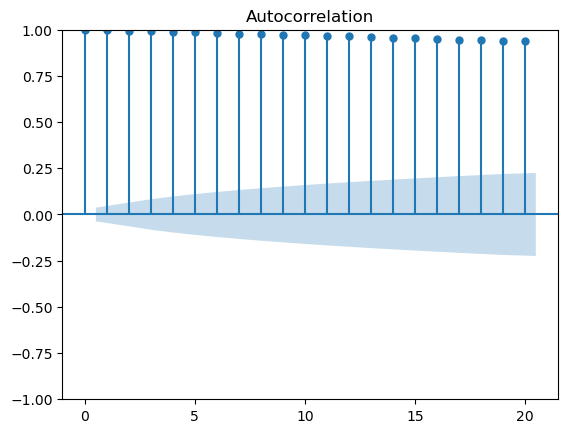

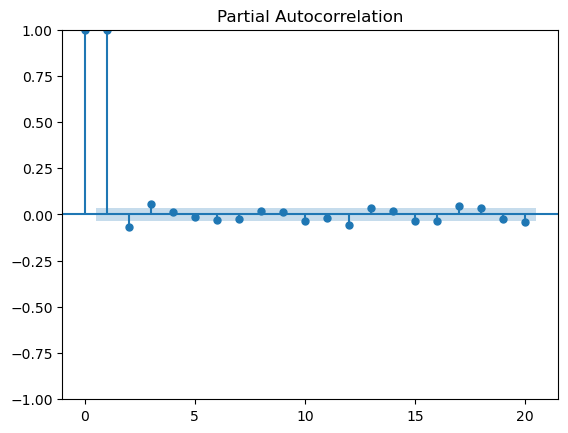

In [ ]:
# plt.plot(y**2)
# plt.show()
plot_acf(y**2,lags=num_lags)
plt.show()
plot_pacf(y**2,lags=num_lags,method="ols")
plt.show()


#######

In [ ]:
box_test2 = sm.stats.acorr_ljungbox(y**2, lags=[20])
print("Ljung-Box for the squares")
box_test2


AttributeError: module 'statsmodels.stats' has no attribute 'acorr_ljungbox'

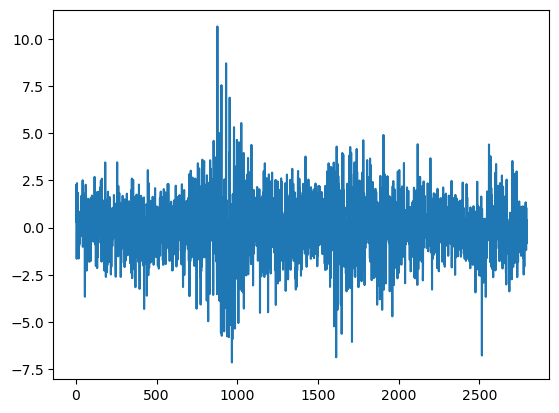

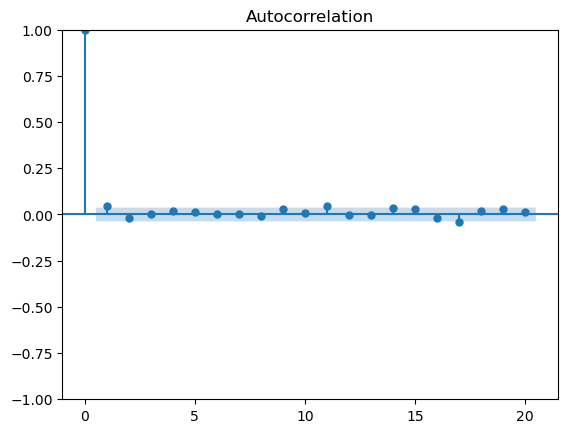

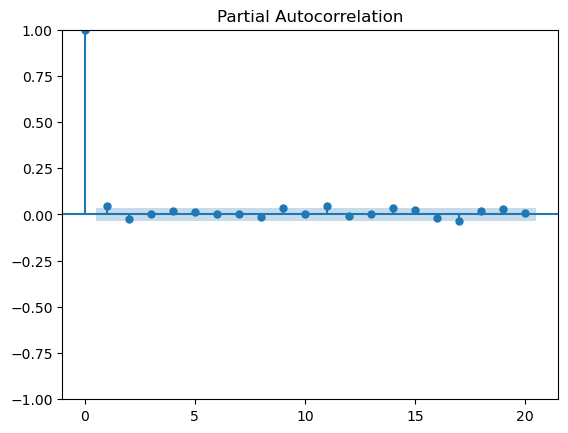

In [ ]:
# In case we have to take some differences to the original series
z = y.diff().dropna()
#z = y.diff(1).diff(1).dropna() # in case we need two differences
plt.plot(z)
plt.show()
plot_acf(z,lags=num_lags)
plt.show()
plot_pacf(z,lags=num_lags)
plt.show()

In [ ]:
box_test_1 = sm.stats.acorr_ljungbox(z, lags=[20])
print("Ljung-Box for z")
print(box_test_1)
box_test_2 = sm.stats.acorr_ljungbox(z**2, lags=[20])
print("Ljung-Box for z**2")
print(box_test_2)

AttributeError: module 'statsmodels.stats' has no attribute 'acorr_ljungbox'

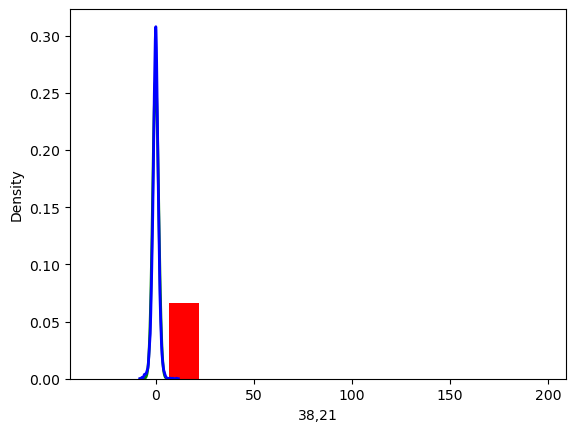

Saphiro ShapiroResult(statistic=0.9777200532112398, pvalue=1.6217698510748606e-20)


In [ ]:
mu = np.mean(z)
sigma = np.std(z)
x = np.linspace(mu -5*sigma, mu +5*sigma, 100)
pdf = st.norm.pdf(x, mu, sigma)
ax = plt.plot(x, pdf, lw = 2, color = "g")
ax = plt.hist(z,density=True, range = (mean - 3*std, mean + 3*std), color = "r")
ax = sns.distplot(z, hist = False, kde = True,
                 kde_kws = {'linewidth': 2}, color = "blue")
ax.set_xlim(mean - 5*std, mean + 5*std)

plt.show()
from scipy.stats import shapiro
# Normality test
saphiro = shapiro(z)

print("Saphiro",saphiro) # first output "The test statistic", second output "p-value"

# Analyzing the real time series

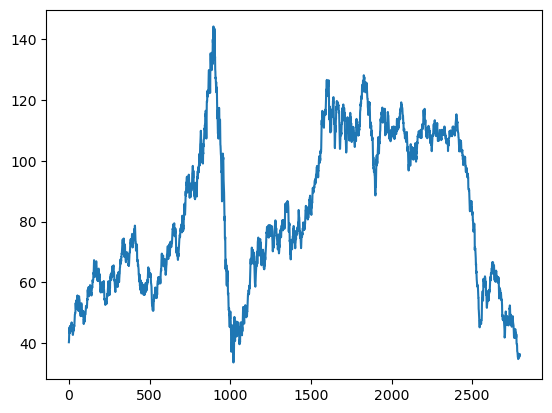

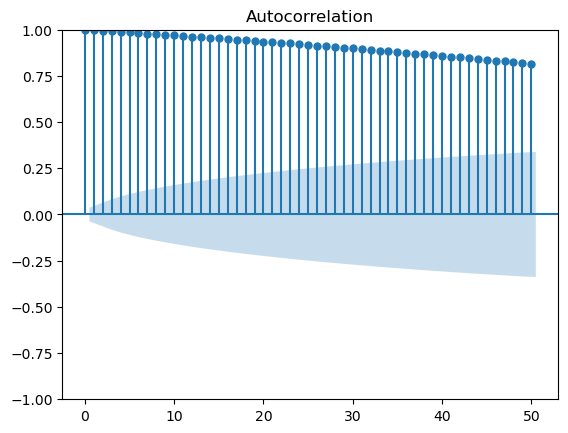

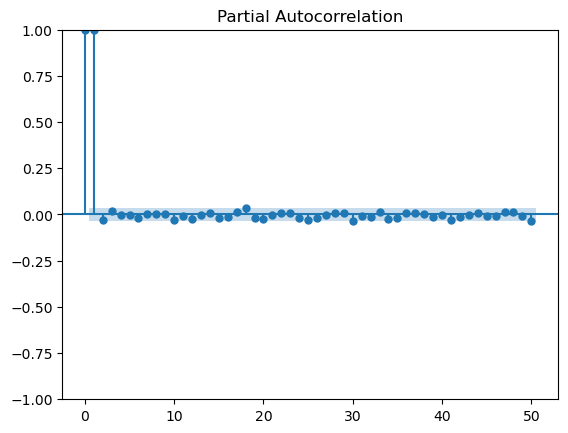

ADF test for the original series
Statistic Value: -1.578690150725415
p-value: 0.4942886750236335


In [ ]:
data = pd.read_csv("Session2real(1).csv", sep = ";", decimal = ",")
# data = pd.read_csv("Individual_Homework.csv", sep = ";", decimal = ",")

spot = data.iloc[:,0]
y = spot

num_lags=50

plt.plot(y)
plt.show()
plot_acf(y,lags=num_lags)
plt.show()
plot_pacf(y,lags=num_lags)
plt.show()

#from pmdarima.arima.utils import ndiffs, nsdiffs
import statsmodels as sm

# Ho: the process is not stationary. We need, at least, a unit root
# H1: the process is stationary. We have to check different models (lags)


adf_test = sm.tsa.stattools.adfuller(y,maxlag=10)
# print("adf_test", adf_test) # first output "The test statistic", second output "p-value"
print("ADF test for the original series")
print("Statistic Value:" , adf_test[0])
print("p-value:" , adf_test[1])
# print(sm.__version__)

In [ ]:
from scipy.stats import kurtosis, skew

# Basic statistics
mean = np.mean(y)
std = np.std(y)
kurtosis = kurtosis(y)
skewness = skew(y)

print("Mean",mean,"Standard deviation",std,"Skewness", skewness, "Kurtosis",kurtosis)


Mean 82.9486373390558 Standard deviation 25.29137540594164 Skewness 0.07675340964475884 Kurtosis -1.273679962331883


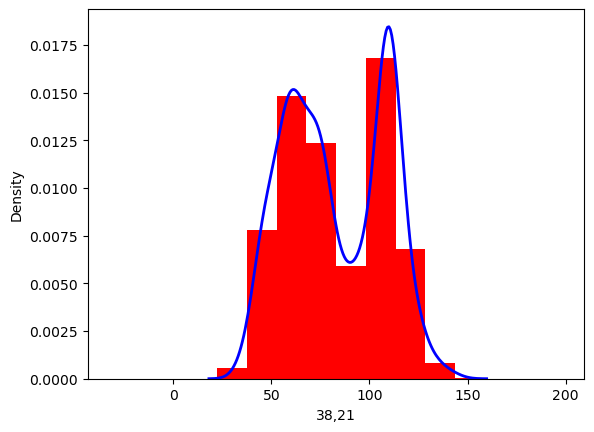

Saphiro ShapiroResult(statistic=0.9430815972724673, pvalue=1.5194055917966208e-31)
mean 82.9486373390558 std 25.29137540594164


In [ ]:
saphiro = shapiro(y)
mean = np.mean(y)
std = np.std(y)
mu = np.mean(y)
sigma = np.std(y)

ax = plt.hist(y,density=True, range = (mean - 3*std, mean + 3*std), color = "r")
ax = sns.distplot(y, hist = False, kde = True,
                 kde_kws = {'linewidth': 2}, color = "blue")
ax.set_xlim(mean - 5*std, mean + 5*std)

plt.show()
print("Saphiro",saphiro)
print("mean",mean,"std",std)

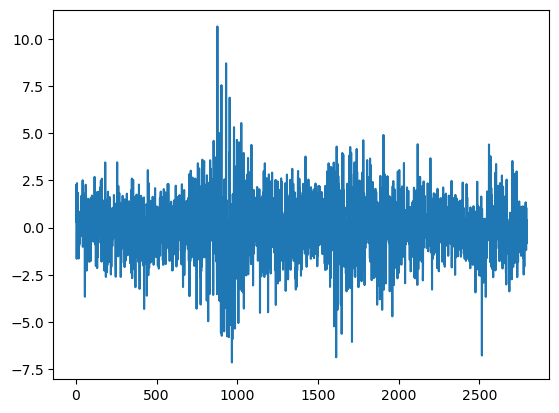

In [ ]:
#returns = np.log(spot).diff().dropna() # we take log first and then one differente, diff(log(spot))
#z = returns
z = y.diff().dropna()

plt.plot(z)

In [1]:
mean = np.mean(z)
std = np.std(z)
mu = np.mean(z)
sigma = np.std(z)
x = np.linspace(mu -5*sigma, mu +5*sigma, 100)
pdf = st.norm.pdf(x, mu, sigma)
ax = plt.plot(x, pdf, lw = 2, color = "g")
ax = plt.hist(z,density=True, range = (mean - 3*std, mean + 3*std), color = "r")
ax = sns.distplot(z, hist = False, kde = True,
                 kde_kws = {'linewidth': 2}, color = "blue")
ax.set_xlim(mean - 5*std, mean + 5*std)

plt.show()

NameError: name 'np' is not defined

In [ ]:
from scipy.stats import kurtosis, skew

# Basic statistics
mean = np.mean(z)
std = np.std(z)
kurtosis = kurtosis(z)
skewness = skew(z)

print("Mean",mean,"Standard deviation",std,"Skewness", skewness, "Kurtosis",kurtosis)


Mean -0.001431127012522364 Standard deviation 1.5298962661400204 Skewness -0.024373659999875383 Kurtosis 2.6244473704341074


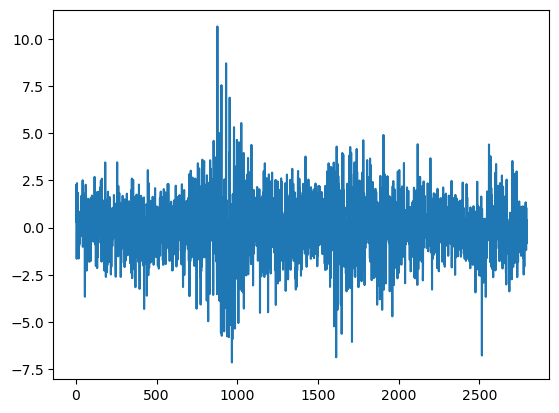

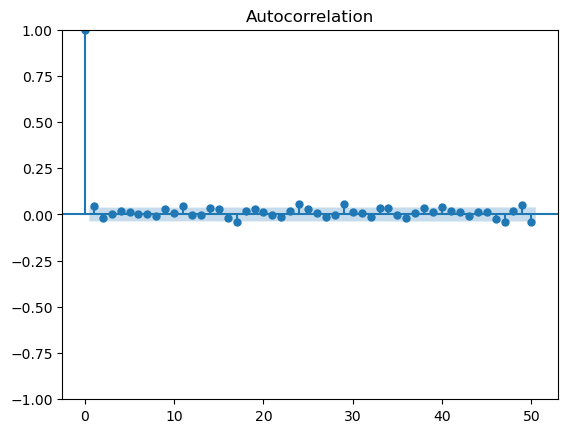

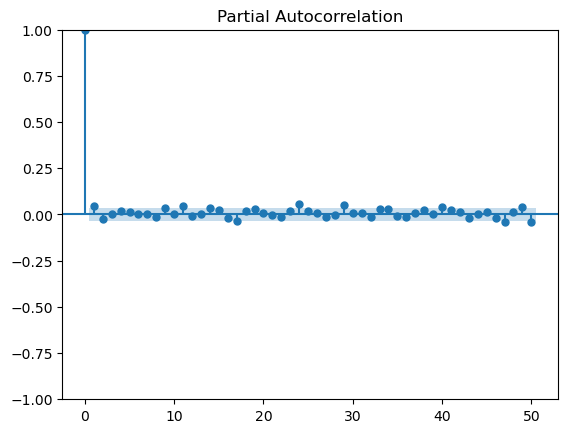

In [ ]:
plt.plot(z)
plt.show()
plot_acf(z,lags=num_lags)
plt.show()
plot_pacf(z,lags=num_lags)
plt.show()

In [ ]:
from scipy.stats import shapiro
# Normality test
saphiro = shapiro(z)

print("Saphiro",saphiro) # first output "The test statistic", second output "p-value"

import statsmodels.api as sm
box_test = sm.stats.acorr_ljungbox(z, lags=[50])
print("Ljung-Box for z")
print(box_test)


Saphiro ShapiroResult(statistic=0.9777200532112398, pvalue=1.6217698510748606e-20)
Ljung-Box for z
      lb_stat  lb_pvalue
50  98.588607    0.00005


In [ ]:
import statsmodels.api as sm
box_test2 = sm.stats.acorr_ljungbox(z**2, lags=[20])
print("Ljung-Box for z**2")
print(box_test2)

Ljung-Box for z**2
       lb_stat      lb_pvalue
20  621.662424  7.823415e-119


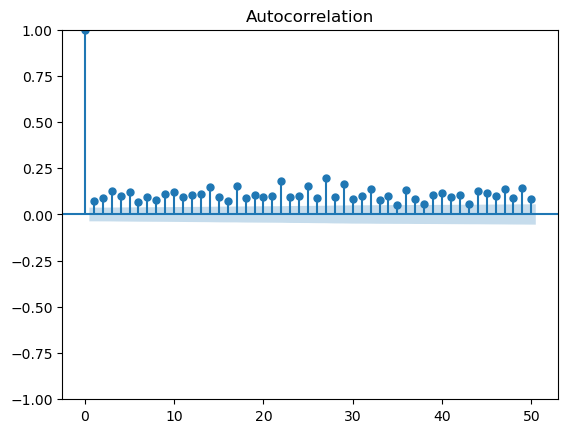

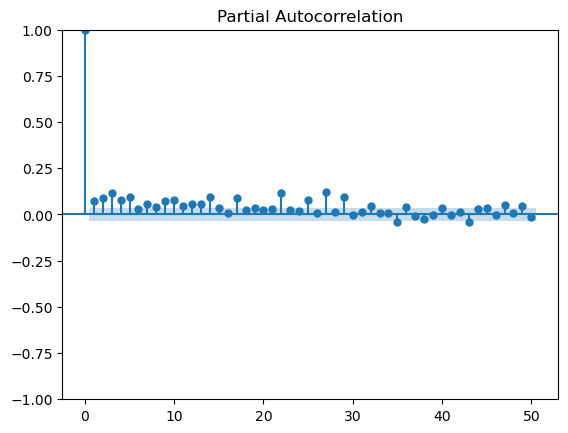

In [ ]:
# plt.plot(z**2)
# plt.show()
plot_acf(z**2,lags=num_lags)
plt.show()
plot_pacf(z**2,lags=num_lags)
plt.show()